## Aspect Ratio 10

## All Aspect Ratios

In [ ]:
import numpy as np
import pandas as pd
import os
import alphashape
from scipy.spatial import KDTree
import re

calculation_alpha_parameter = 1.1


def extract_aspect_ratios_from_path(path):
    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)
    if not match:
        return None
    asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
    asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
    return asp1, asp2

def generate_points_along_rod(xi, yi, length, orientation, num_points=5):
    dx = (length / 2) * np.cos(orientation)
    dy = (length / 2) * np.sin(orientation)
    t = np.linspace(0, 1, num_points)
    return np.column_stack([(xi - dx + 2 * dx * ti, yi - dy + 2 * dy * ti) for ti in t]).T

def calculate_periphery(x, y, lengths, orientations, alpha):
    rod_endpoints = np.empty((2 * len(x), 2))
    for i, (xi, yi, length, orientation) in enumerate(zip(x, y, lengths, orientations)):
        dx = (length / 2) * np.cos(orientation)
        dy = (length / 2) * np.sin(orientation)
        rod_endpoints[2 * i] = (xi - dx, yi - dy)
        rod_endpoints[2 * i + 1] = (xi + dx, yi + dy)
    if rod_endpoints.shape[1] != 2:
        rod_endpoints = rod_endpoints.T
    return alphashape.alphashape(rod_endpoints, alpha)

def count_periphery_cells(x, y, lengths, orientations, color2, hull, distance_threshold):
    hull_points = np.array(hull.exterior.xy).T
    kdtree = KDTree(hull_points)
    periphery_count_asp1, periphery_count_asp2 = 0, 0
    for xi, yi, length, orientation, col2 in zip(x, y, lengths, orientations, color2):
        rod_points = generate_points_along_rod(xi, yi, length, orientation)
        for point in rod_points:
            distance_to_hull, _ = kdtree.query(point)
            if distance_to_hull <= distance_threshold:
                if col2 == 0:
                    periphery_count_asp1 += 1
                else:
                    periphery_count_asp2 += 1
                break
    return periphery_count_asp1, periphery_count_asp2


results_per_aspect_ratio = {}
distance_threshold = 2

base_path = "/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime"
aspect_folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]

for trial in range(1, 6):
    for aspect_folder in aspect_folders:
        trial_path = os.path.join(base_path, aspect_folder, f"run{trial}")
        if not os.path.exists(trial_path):
            continue

        subfolders = [f.path for f in os.scandir(trial_path) if f.is_dir()]

        for subfolder in subfolders:
            aspect_ratios = extract_aspect_ratios_from_path(subfolder)
            if aspect_ratios is None:
                continue
            asp1, asp2 = aspect_ratios

            csv_files = sorted(
                [f for f in os.listdir(subfolder) if f.endswith('.csv') and f.strip('.csv').isdigit()],
                key=lambda f: int(f.strip('.csv'))
            )
            if not csv_files:
                continue

            output1_temp, output2_temp, times_temp = [], [], []

            for time_file in csv_files:
                time = int(time_file.strip('.csv'))
                df = pd.read_csv(f"{subfolder}/{time_file}")
                x, y, ex, ey, lengths, color2 = df[["x", "y", "ex", "ey", "l", "color2"]].T.values
                orientations = np.arctan2(ey, ex)

                try:
                    hull = calculate_periphery(x, y, lengths, orientations, alpha=calculation_alpha_parameter)
                except Exception:
                    continue

                periphery_count_asp1, periphery_count_asp2 = count_periphery_cells(
                    x, y, lengths, orientations, color2, hull, distance_threshold
                )

                total_cells = periphery_count_asp1 + periphery_count_asp2
                if total_cells == 0:
                    continue

                output1_temp.append(periphery_count_asp1 / total_cells)
                output2_temp.append(periphery_count_asp2 / total_cells)
                times_temp.append(time)

            if not output1_temp:
                continue

            aspect_ratio_key = (asp1, asp2)
            if aspect_ratio_key not in results_per_aspect_ratio:
                results_per_aspect_ratio[aspect_ratio_key] = {"output1": [], "output2": [], "times": []}

            results_per_aspect_ratio[aspect_ratio_key]["output1"].append(output1_temp)
            results_per_aspect_ratio[aspect_ratio_key]["output2"].append(output2_temp)
            results_per_aspect_ratio[aspect_ratio_key]["times"].append(times_temp)


averaged_results = {}
for key, data in results_per_aspect_ratio.items():
    all_times = sorted(set(t for trial_times in data["times"] for t in trial_times))
    avg_output1, sem_output1 = [], []

    for time in all_times:
        trial_outputs = [
            data["output1"][trial_idx][data["times"][trial_idx].index(time)]
            for trial_idx, trial_times in enumerate(data["times"])
            if time in trial_times
        ]
        avg_output1.append(np.mean(trial_outputs))
        sem_output1.append(np.std(trial_outputs) / np.sqrt(len(trial_outputs)))

    averaged_results[key] = {"avg_output1": avg_output1, "sem_output1": sem_output1, "times": all_times}


all_results = []
for (asp1, asp2), data in averaged_results.items():
    for i, time in enumerate(data["times"]):
        all_results.append({
            "Aspect_Ratio_1": asp1,
            "Aspect_Ratio_2": asp2,
            "Time": time / 5e5,
            "Avg_Fraction_Asp1": data["avg_output1"][i],
            "SEM_Avg_Fraction_Asp1": data["sem_output1"][i]
        })

df_results = pd.DataFrame(all_results)
df_results.to_csv("MAR26_all_aspects_periphery_fractions_w=20d.csv", index=False)

Done: asp1=10.0, asp2=4.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=5.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=3.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=2.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=6.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=8.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=7.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=9.0, trial path=/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1
Done: asp1=10.0, asp2=10.0, trial path=/Volumes/T7/activeMatterC

## Radial Order Periphery Tracker

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import os
import re
import tools.tracking.ancestors_with_bulk as ancestorTracker
from routines.parameterTable import parameterTable


BASE_PATH = "/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/workspace/simulations_eqdivtime/asp10"


def create_black_centered_cmap():
    colors = ["#0000FF", "black", "#FFD700"]
    return LinearSegmentedColormap.from_list("black_centered", colors, N=500)


def extract_aspect_ratios_from_path(path):
    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)
    if not match:
        return None
    asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
    asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
    return asp1, asp2


PERIPHERY_DISTANCE_THRESHOLD = 0.5

def radial_timeseries_by_group(sample_path, n_bulk=1000, seed=None):
    from tools.dataAPI.datamodel import DataModel
    actual_times = DataModel.extract_times(sample_path)[1]

    peri_trajectories, bulk_trajectories = ancestorTracker.fetch_trajectories_all(
        sample_path, n_bulk=n_bulk, seed=seed
    )

    periphery_by_t = {}
    bulk_by_t = {}

    for traj in peri_trajectories:
        arrival_idx = None
        for t_idx in range(len(traj.front_displacement)):
            if traj.front_displacement[t_idx] < PERIPHERY_DISTANCE_THRESHOLD:
                arrival_idx = t_idx
                break

        cutoff = arrival_idx if arrival_idx is not None else len(traj.x)

        for t_idx in range(cutoff):
            theta  = np.arctan2(traj.ey[t_idx], traj.ex[t_idx])
            phi    = np.arctan2(traj.y[t_idx],  traj.x[t_idx])
            sr     = np.cos(2 * (theta - phi))
            real_t = actual_times[t_idx] if t_idx < len(actual_times) else t_idx
            periphery_by_t.setdefault(real_t, []).append(sr)

    for traj in bulk_trajectories:
        for t_idx in range(len(traj.x)):
            theta  = np.arctan2(traj.ey[t_idx], traj.ex[t_idx])
            phi    = np.arctan2(traj.y[t_idx],  traj.x[t_idx])
            sr     = np.cos(2 * (theta - phi))
            real_t = actual_times[t_idx] if t_idx < len(actual_times) else t_idx
            bulk_by_t.setdefault(real_t, []).append(sr)

    return periphery_by_t, bulk_by_t


def mean_sem(values_by_t):
    times = sorted(values_by_t)
    means, sems = [], []
    for t in times:
        vals = np.array(values_by_t[t])
        means.append(np.nanmean(vals))
        n = np.sum(~np.isnan(vals))
        sems.append(np.nanstd(vals) / np.sqrt(n) if n > 1 else 0.0)
    return np.array(times), np.array(means), np.array(sems)


df_params = parameterTable(BASE_PATH)

results = {}

for sample_path in df_params.basePath.values:
    aspect_ratios = extract_aspect_ratios_from_path(sample_path)
    if aspect_ratios is None:
        continue
    asp1, asp2 = aspect_ratios

    if not (asp1 == 10.0 or asp2 == 10.0):
        continue

    key = (10.0, asp2) if asp1 == 10.0 else (10.0, asp1)

    peri_by_t, bulk_by_t = radial_timeseries_by_group(sample_path, n_bulk=1000, seed=1)

    if key not in results:
        results[key] = {"periphery": {}, "bulk": {}}

    for t, vals in peri_by_t.items():
        results[key]["periphery"].setdefault(t, []).append(np.nanmean(vals))
    for t, vals in bulk_by_t.items():
        results[key]["bulk"].setdefault(t, []).append(np.nanmean(vals))

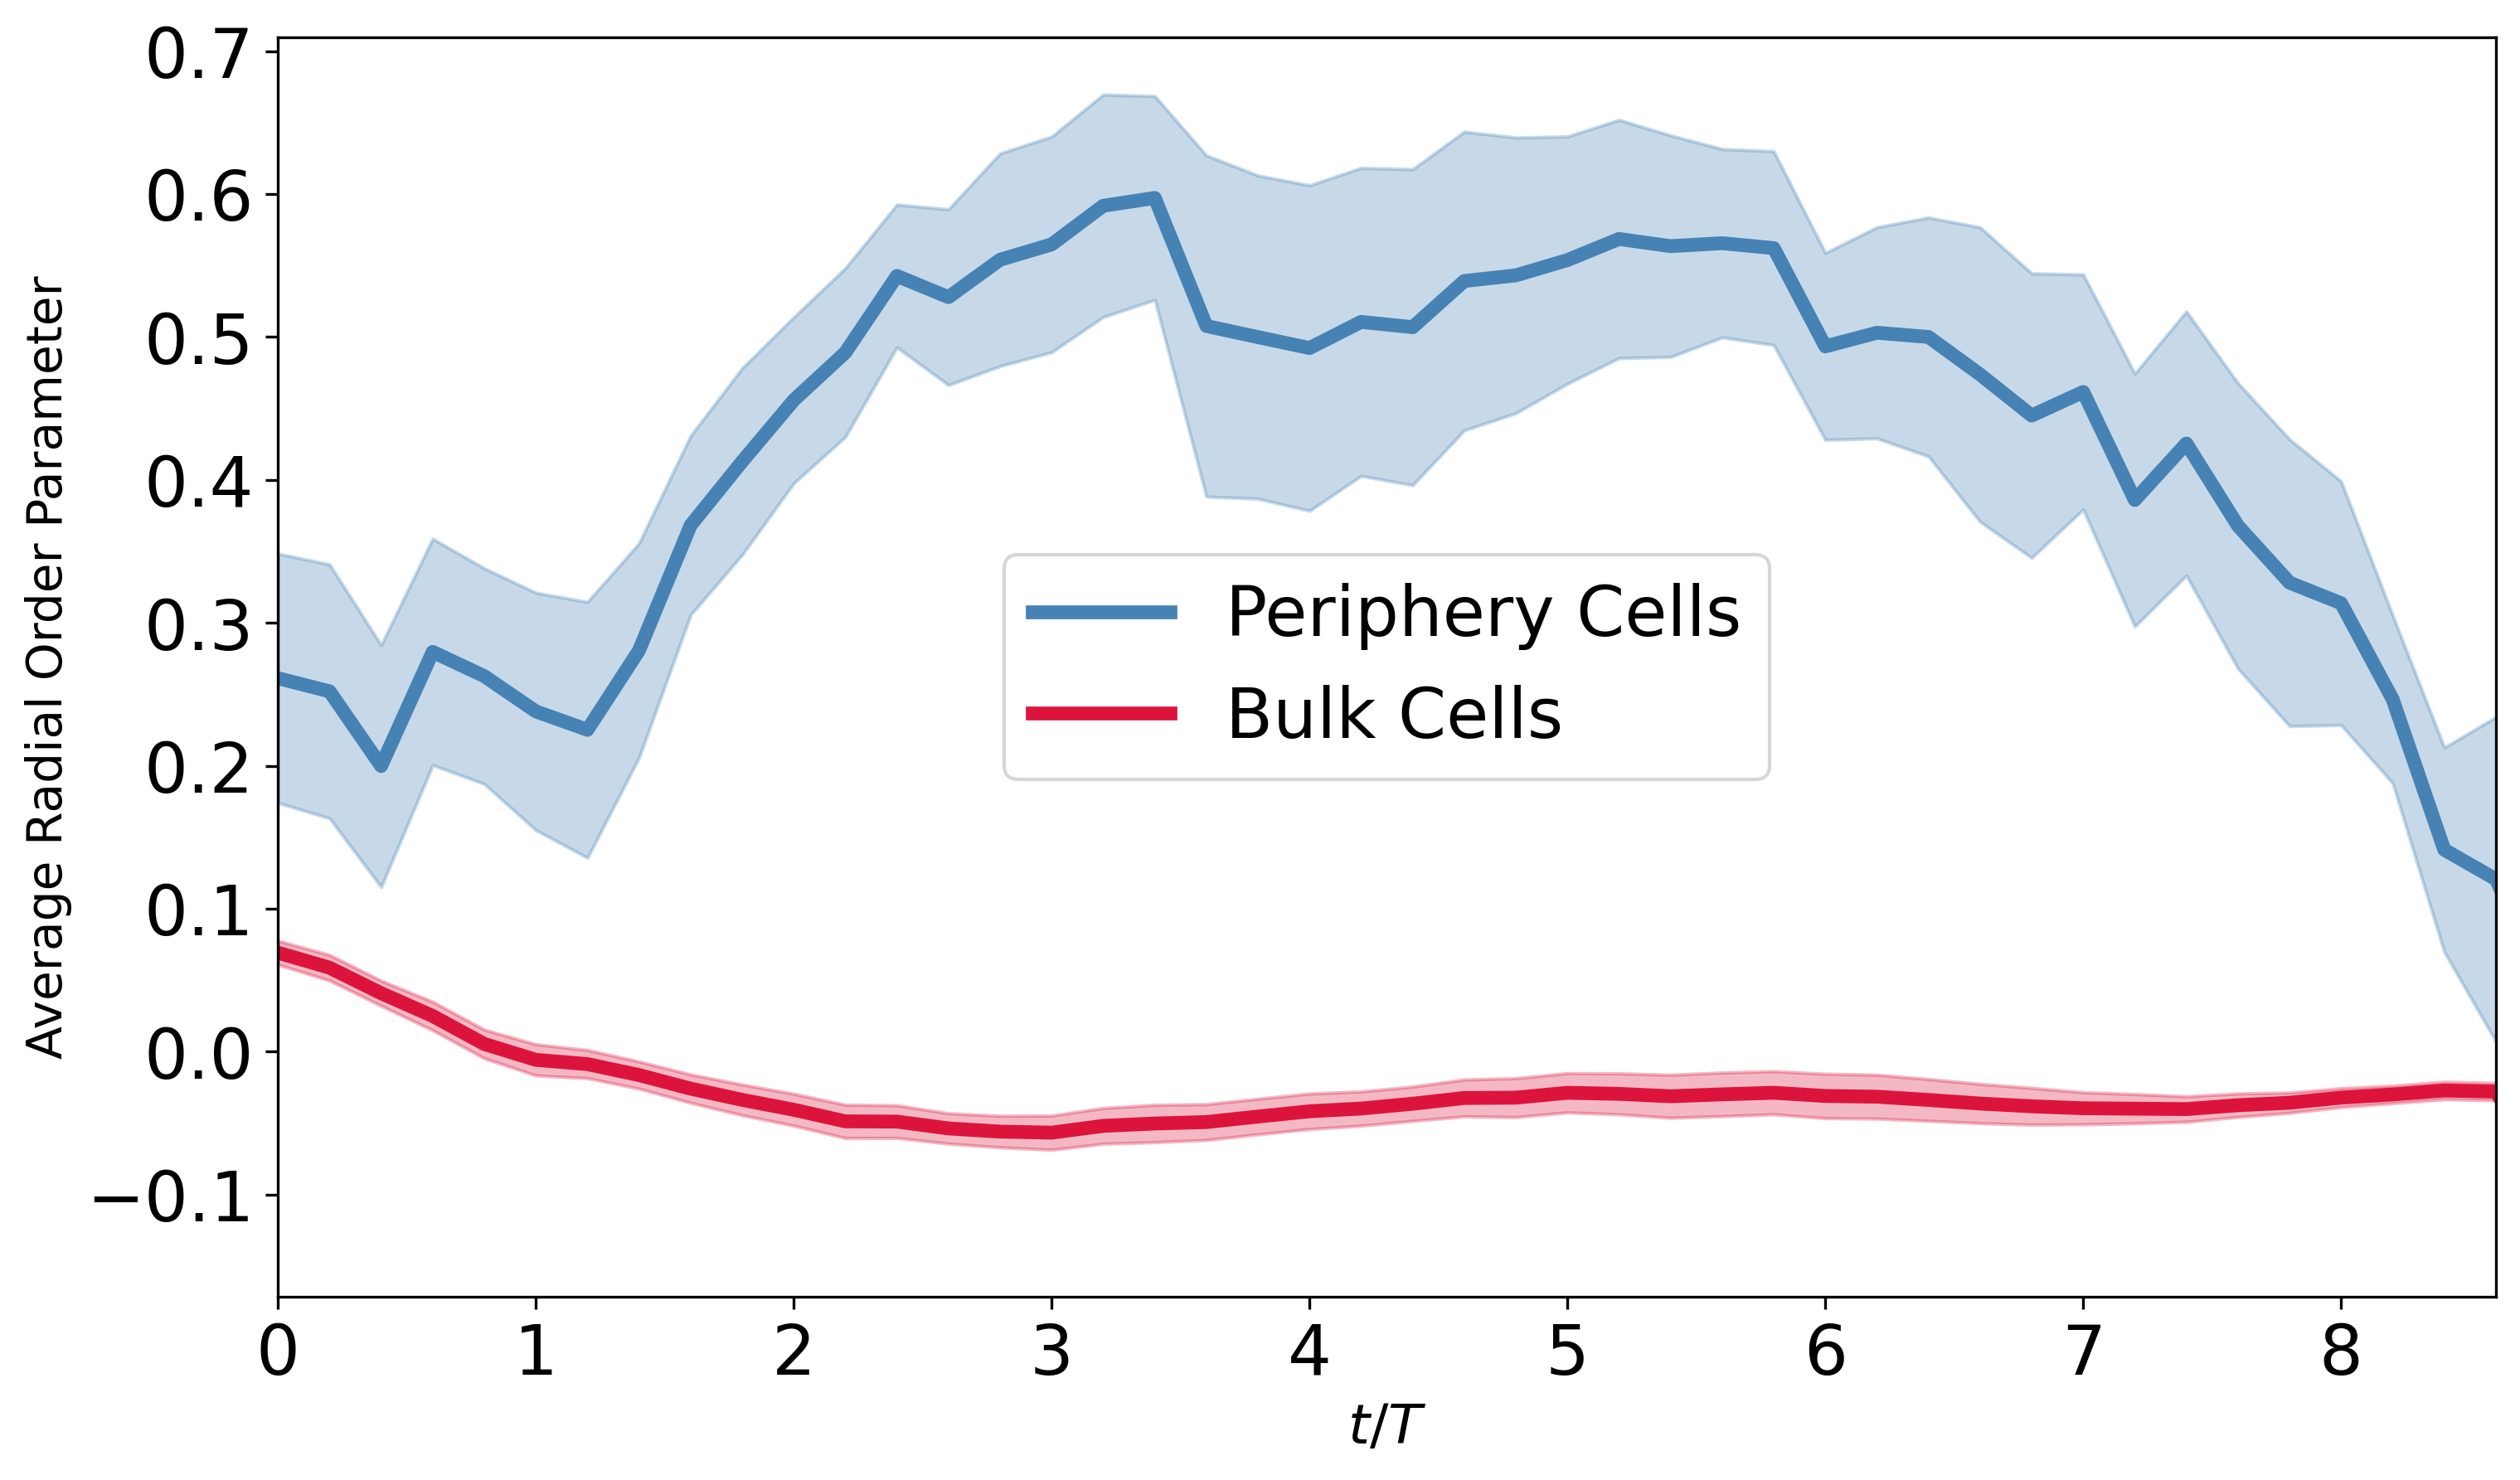

In [2]:
from collections import defaultdict
filtered = {key: data for key, data in results.items()}

condition_means_p = defaultdict(list)  
condition_means_b = defaultdict(list)

for (asp1, asp2), data in filtered.items():
    t_p, m_p, _ = mean_sem(data["periphery"])
    t_b, m_b, _ = mean_sem(data["bulk"])

    for t, m in zip(t_p, m_p):
        condition_means_p[t].append(m)
    for t, m in zip(t_b, m_b):
        condition_means_b[t].append(m)

times_p, means_p, sems_p = mean_sem(condition_means_p)
times_b, means_b, sems_b = mean_sem(condition_means_b)

times_p_scaled = times_p / 20e5
times_b_scaled = times_b / 20e5

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

ax.plot(times_p_scaled, means_p, color='steelblue', linewidth=4, label='Periphery Cells')
ax.fill_between(times_p_scaled, means_p - sems_p, means_p + sems_p, color='steelblue', alpha=0.3)

ax.plot(times_b_scaled, means_b, color='crimson', linewidth=4, label='Bulk Cells')
ax.fill_between(times_b_scaled, means_b - sems_b, means_b + sems_b, color='crimson', alpha=0.3)

ax.set_xlabel(r"$t/T$", fontsize=16)
ax.set_ylabel(r"Average Radial Order Parameter", fontsize=14)
ax.set_xlim(0, 8.6)
ax.set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8])
ax.tick_params(axis='both', which='major', labelsize=20)
ax.legend(fontsize=20)

plt.tight_layout()
plt.savefig("GRAPH_RADIAL_COR_PERIPHERY_VS_BULK_GRAND_AVG.png", bbox_inches='tight', dpi=300)
plt.show()

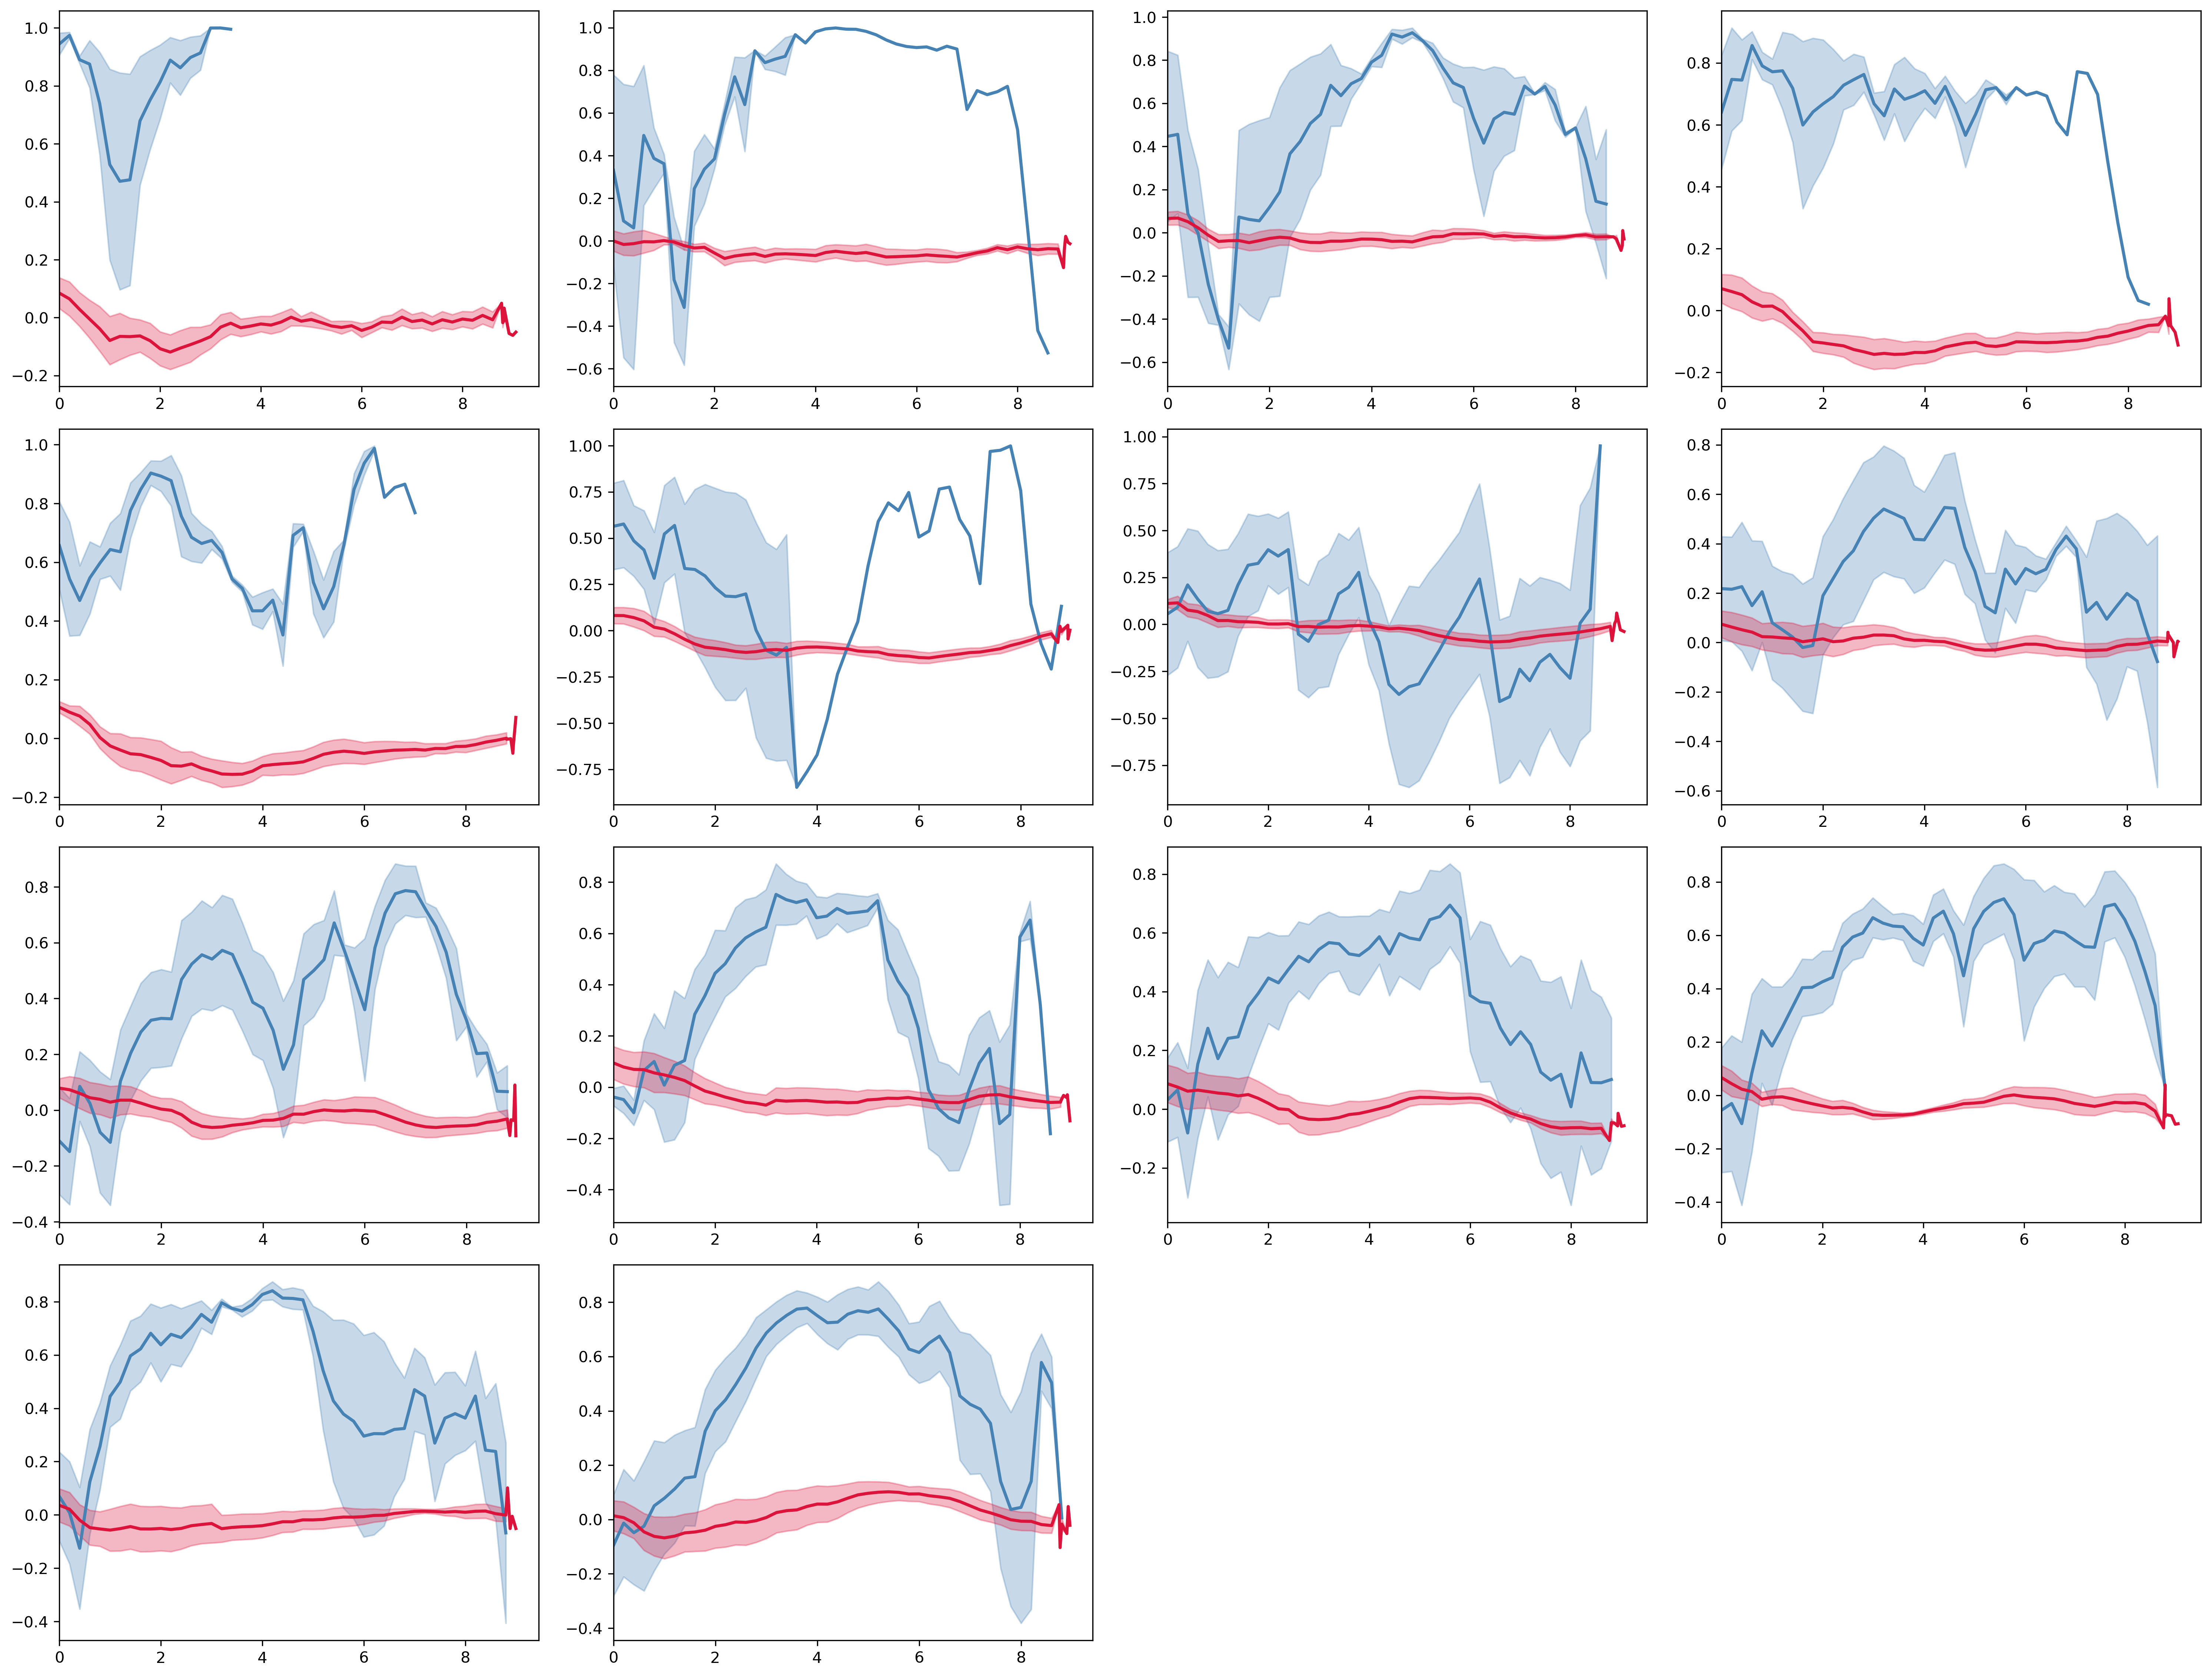

In [3]:
from collections import defaultdict
import math

filtered = {key: data for key, data in results.items()}
items = sorted(filtered.items(), key=lambda x: x[0][1])
n = len(items)

ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows), dpi=300)
axes = axes.flatten() 

for i, ((A, B), data) in enumerate(items):
    ax = axes[i]

    t_p, m_p, s_p = mean_sem(data["periphery"])
    t_b, m_b, s_b = mean_sem(data["bulk"])

    
    t_p_scaled = t_p / 20e5
    t_b_scaled = t_b / 20e5

    ax.plot(t_p_scaled, m_p, color='steelblue', linewidth=2, label='Periphery')
    ax.fill_between(t_p_scaled, m_p - s_p, m_p + s_p,
                    color='steelblue', alpha=0.3)

    ax.plot(t_b_scaled, m_b, color='crimson', linewidth=2, label='Bulk')
    ax.fill_between(t_b_scaled, m_b - s_b, m_b + s_b,
                    color='crimson', alpha=0.3)

    ax.set_xlim(0, max(t_b_scaled.max(), t_p_scaled.max()) * 1.05)
    ax.set_xticks([0, 2, 4, 6, 8])
    ax.tick_params(axis='both', labelsize=10)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(rect=[0, 0, 1, 0.95])  
plt.show()

## Correlation of Radial Order and Final Distance

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import re
import tools.tracking.ancestors_with_bulk as ancestorTracker
from routines.parameterTable import parameterTable
from tools.dataAPI.datamodel import DataModel

BASE_PATH = "/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/workspace/simulations_eqdivtime/asp10"
DIVISION_TIME = 2e5
TARGET_TIME = 3 * DIVISION_TIME
N_SAMPLE = 1000
UNIT = 0.1

def extract_aspect_ratios_from_path(path):
    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)
    if not match:
        return None
    asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
    asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
    return asp1, asp2


def sr_vs_final_distance(sample_path, n_sample=N_SAMPLE, seed=None):
    actual_times = np.array(DataModel.extract_times(sample_path)[1], dtype=int)
    target_idx = int(np.argmin(np.abs(actual_times - TARGET_TIME)))

    rng = np.random.default_rng(seed)
    from tools.dataModels.measurements import Measurements
    from tools.tracking.ancestors_with_bulk import (
        fetch_data, fetch_bulk_cells, fetch_boundary_coords,
        perpendicular_distance, create_initial_snapshot_from_indices,
        fetch_history, conform, map_allele_to_population
    )

    ref_data, indx = fetch_data(sample_path, actual_times.tolist())
    n_total = ref_data.l.size
    sampled_indices = rng.choice(n_total, size=min(n_sample, n_total), replace=False)
    sampled_indices = np.sort(sampled_indices)

    alleleMapping = map_allele_to_population(sample_path, actual_times.tolist())
    history = create_initial_snapshot_from_indices(sample_path, actual_times.tolist(), sampled_indices)
    fetch_history(sample_path, actual_times.tolist(), history)
    trajectories = conform(history, alleleMapping, is_bulk=False)

    sr_vals, dist_vals = [], []
    for traj in trajectories:
        if target_idx >= len(traj.x):
            continue
        theta = np.arctan2(traj.ey[target_idx], traj.ex[target_idx])
        phi   = np.arctan2(traj.y[target_idx],  traj.x[target_idx])
        sr    = np.cos(2 * (theta - phi))
        final_dist = traj.front_displacement[-1] / UNIT
        sr_vals.append(sr)
        dist_vals.append(final_dist)

    return np.array(sr_vals), np.array(dist_vals)


df_params = parameterTable(BASE_PATH)

all_sr, all_dist = [], []

for sample_path in df_params.basePath.values:
    aspect_ratios = extract_aspect_ratios_from_path(sample_path)
    if aspect_ratios is None:
        continue
    asp1, asp2 = aspect_ratios

    if not (asp1 == 10.0 or asp2 == 10.0):
        continue

    sr_vals, dist_vals = sr_vs_final_distance(sample_path, seed=1)

    all_sr.append(sr_vals)
    all_dist.append(dist_vals)

all_sr   = np.concatenate(all_sr)   if all_sr   else np.array([])
all_dist = np.concatenate(all_dist) if all_dist else np.array([])

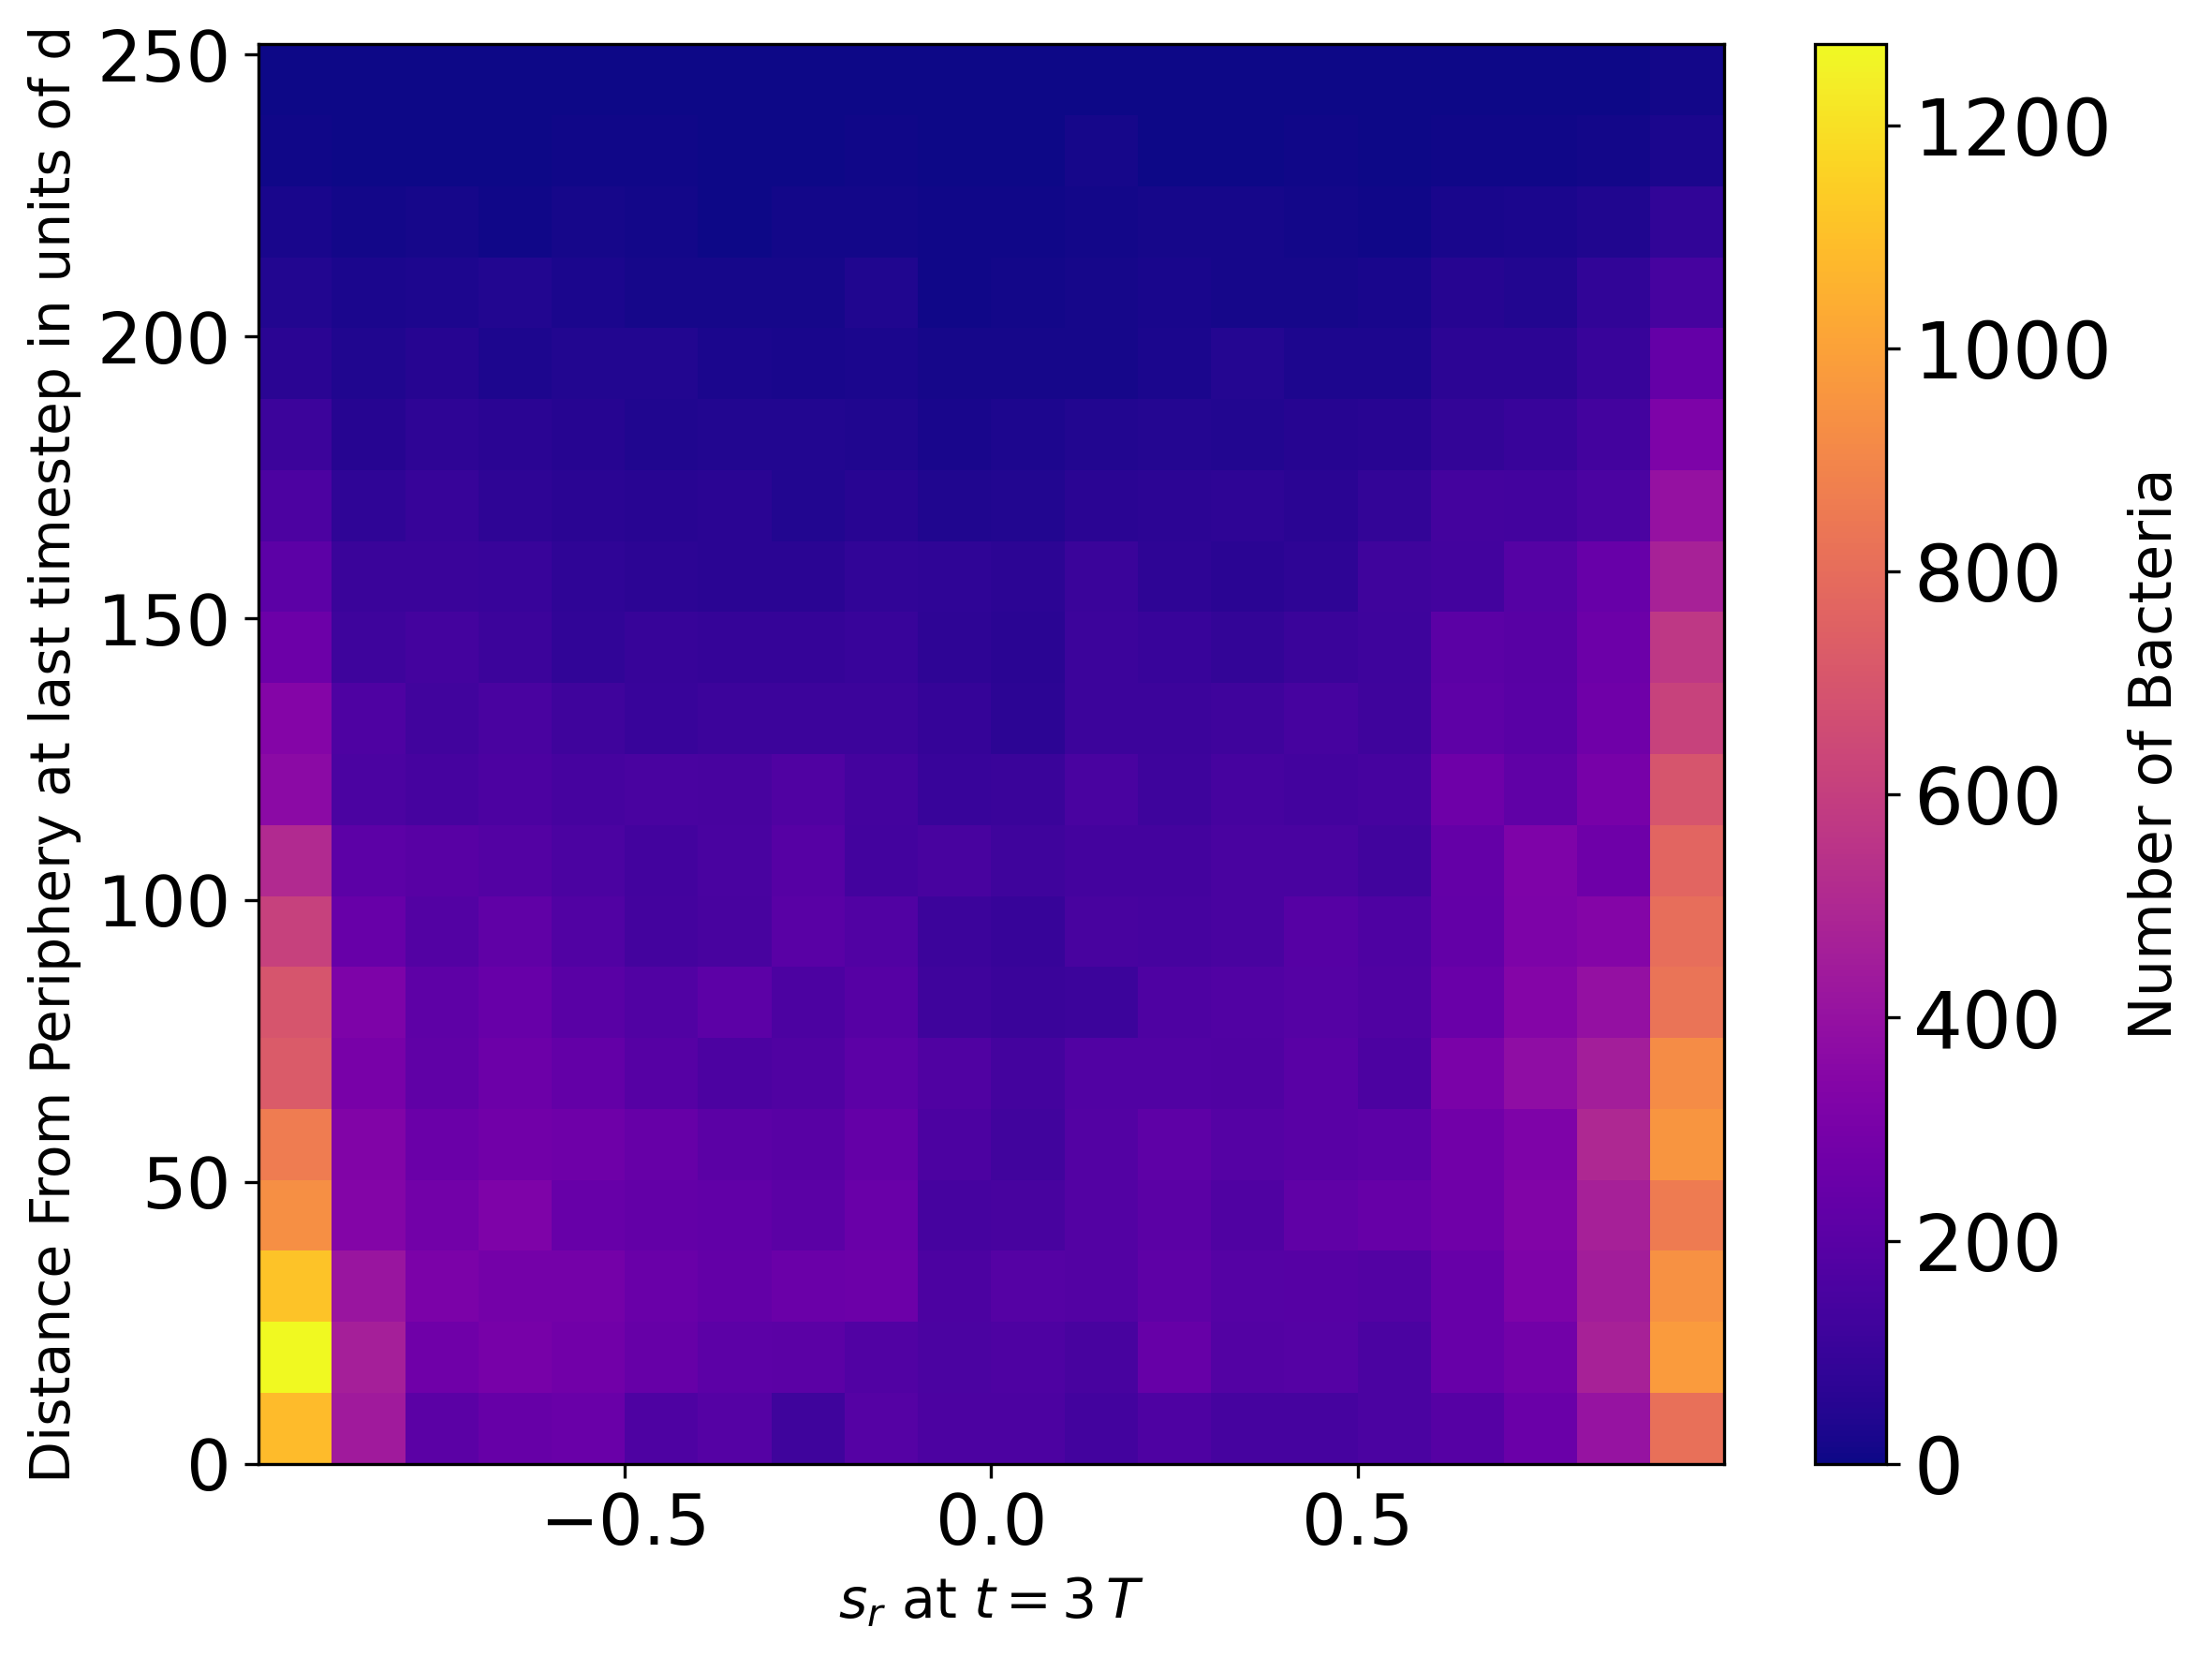

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
h, xedges, yedges, img = ax.hist2d(all_sr, all_dist, bins=20, cmap='plasma')
cb = fig.colorbar(img, ax=ax)
cb.set_label('Number of Bacteria', fontsize=15)
cb.ax.tick_params(labelsize=20)
ax.set_xlabel(r"$s_r$ at $t = 3\,T$", fontsize=14)
ax.set_ylabel(r"Distance From Periphery at last timestep (d)", fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=18)

plt.tight_layout()
plt.show()